# Results

Every figure and table in the report is built here from the CSVs in `results/`. This notebook never
trains models or runs detectors itself; rerun the scripts in `experiments/` to refresh the inputs.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
R, FIG = ROOT / "results", ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
FAMILY = {"adwin": COLORS[0], "adwin_demand": COLORS[1], "psi": COLORS[2], "page_hinkley": COLORS[3], "kswin": COLORS[4]}
plt.rcParams.update({"figure.dpi": 130, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "lines.linewidth": 1.6, "legend.frameon": False})
S = {}  # headline numbers, saved for the report and the slides

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=200)
    plt.show()

## 1. Forecasting model against the baseline

In [2]:
base = pd.read_csv(R / "model" / "baseline_metrics.csv")
display(base.round(2))
city = base[base.scope == "city"].set_index("model")
S["model_wape"], S["naive_wape"] = float(city.wape["lightgbm"]), float(city.wape["seasonal_naive"])

,model,split,scope,mae,smape,wape
0,lightgbm,Oct-Dec 2019,city,4.71,120.09,13.14
1,seasonal_naive,Oct-Dec 2019,city,7.89,53.23,22.00
2,lightgbm,Oct-Dec 2019,Bronx,0.45,168.24,114.31
3,seasonal_naive,Oct-Dec 2019,Bronx,0.48,62.91,122.63
4,lightgbm,Oct-Dec 2019,Brooklyn,0.99,127.84,55.09
5,seasonal_naive,Oct-Dec 2019,Brooklyn,1.26,76.64,70.30
6,lightgbm,Oct-Dec 2019,Manhattan,14.79,42.63,11.79
7,seasonal_naive,Oct-Dec 2019,Manhattan,25.87,32.04,20.62
8,lightgbm,Oct-Dec 2019,Queens,1.99,137.63,21.14
9,seasonal_naive,Oct-Dec 2019,Queens,2.77,60.79,29.44


## 2. Big data measurements

In [3]:
p = R / "scaling" / "batch_scaling.csv"
if p.exists():
    b = pd.read_csv(p).groupby(["workers", "cores"], as_index=False).seconds.median()
    b["speedup"] = b.seconds.iloc[0] / b.seconds
    display(b.round(2))
    S["batch"] = b.round(2).to_dict("records")
    fig, ax = plt.subplots(figsize=(4.6, 2.8))
    ax.bar(b.workers.astype(str), b.seconds, color=COLORS[0], width=0.5)
    for x, v in zip(range(len(b)), b.seconds):
        ax.annotate(f"{v:.0f}s", (x, v), ha="center", va="bottom", xytext=(0, 2), textcoords="offset points")
    ax.set(xlabel="Spark workers (2 cores each)", ylabel="Seconds", title="Zone-hour batch build, 2019-2021")
    ax.grid(axis="x", visible=False)
    save(fig, "batch_scaling")

In [4]:
for name in ["stream_throughput", "storage", "pruning", "detector_cost", "stream_latency"]:
    p = R / "scaling" / f"{name}.csv"
    if p.exists():
        d = pd.read_csv(p)
        if name == "pruning":
            d = d.groupby("query", as_index=False).seconds.median()
        if name == "stream_latency":
            d = d.groupby("speedup", as_index=False).processing_latency.describe()
        print(name)
        display(d.round(2))
        S[name] = json.loads(d.round(3).to_json(orient="records"))
p = R / "stream" / "spark_progress.csv"
if p.exists():
    sp = pd.read_csv(p)
    sp = sp[sp.input_rows > 0]
    S["stream_demo_rate_median"] = float(sp.processed_rate.median())
    S["stream_demo_rows"] = int(sp.input_rows.sum())
    print("demo stream: rows", S["stream_demo_rows"], "median processed rows/s", round(S["stream_demo_rate_median"]))

demo stream: rows 3245202 median processed rows/s 1819


## 3. Detector comparison (synthetic drift with a known change point)

In [5]:
bench = pd.read_csv(R / "detectors" / "benchmark.csv")
# False alarms: no-drift runs, city stream
nd = bench[(bench.scenario == "no_drift") & (bench.stream_scope == "city")]
fa = nd.groupby(["family", "detector"], as_index=False).agg(alarms=("false_alarms", "sum"), hours=("hours_watched", "sum"))
fa["false_alarms_per_1000h"] = 1000 * fa.alarms / fa.hours
# Detection: city-wide drift, city stream
dr = bench[(bench.target == "city") & (bench.stream_scope == "city")]
det = dr.groupby("detector").agg(detection_rate=("detected", "mean"), median_delay_h=("delay", "median"))
table = fa.merge(det, on="detector")[["family", "detector", "false_alarms_per_1000h", "detection_rate", "median_delay_h"]]
display(table.round(2))
S["detectors"] = json.loads(table.round(3).to_json(orient="records"))

fig, ax = plt.subplots(figsize=(5.6, 3.2))
for fam, g in table.groupby("family"):
    ax.scatter(g.false_alarms_per_1000h, g.median_delay_h, s=38, color=FAMILY.get(fam, "#777"), label=fam,
               edgecolor="white", linewidth=1.2, zorder=3)
ax.set(xlabel="False alarms per 1000 hours (no-drift runs)", ylabel="Median detection delay (hours)",
       title="Detection delay against false alarms, city-wide drift")
ax.legend(fontsize=8)
save(fig, "detector_tradeoff")

by = dr.pivot_table(index="scenario", columns="family", values="delay", aggfunc="median").round(0)
rate = dr.pivot_table(index="scenario", columns="family", values="detected", aggfunc="mean").round(2)
print("median delay (h) by scenario"); display(by)
print("detection rate by scenario"); display(rate)
S["delay_by_scenario"] = json.loads(by.reset_index().to_json(orient="records"))
S["rate_by_scenario"] = json.loads(rate.reset_index().to_json(orient="records"))

,family,detector,false_alarms_per_1000h,detection_rate,median_delay_h
0,adwin,adwin_d0.002,4.42,1.00,26.5
1,adwin,adwin_d0.01,4.81,1.00,24.5
2,adwin,adwin_d0.05,6.85,1.00,23.5
3,adwin_demand,adwin_demand_d0.002,3.62,1.00,38.5
4,kswin,kswin_a0.0005,10.70,1.00,28.5
5,kswin,kswin_a0.005,12.40,1.00,37.0
6,page_hinkley,page_hinkley_t10,5.26,1.00,7.0
7,page_hinkley,page_hinkley_t20,2.26,1.00,17.0
8,page_hinkley,page_hinkley_t5,11.21,1.00,2.0
9,psi,psi_t0.1,0.45,0.03,171.0


<Figure size 728x416 with 1 Axes>

median delay (h) by scenario


family,adwin,adwin_demand,kswin,page_hinkley,psi
scenario,,,,,
abrupt_down_50pct,25.0,32.0,37.0,2.0,NaN
abrupt_up_50pct,23.0,28.0,24.0,11.0,NaN
gradual_down_50pct,54.0,149.0,55.0,66.0,183.0
profile_shift_3h,15.0,36.0,18.0,6.0,NaN


detection rate by scenario


family,adwin,adwin_demand,kswin,page_hinkley,psi
scenario,,,,,
abrupt_down_50pct,1.0,1.0,1.0,1.0,0.00
abrupt_up_50pct,1.0,1.0,1.0,1.0,0.00
gradual_down_50pct,1.0,1.0,1.0,1.0,0.29
profile_shift_3h,1.0,1.0,1.0,1.0,0.00


## 4. Real drift: COVID-19, fixed 2019 model

In [6]:
cov = pd.read_csv(R / "detectors" / "covid_alarms.csv")
display(cov[cov.scope == "city"].round(1))
S["covid_city"] = json.loads(cov[cov.scope == "city"].round(1).to_json(orient="records"))

,detector,scope,alarms_before_march,first_alarm_after_mar1,hours_from_mar15,total_alarms
0,adwin_d0.002,city,12,2020-03-12 23:00:00,-49.0,31
1,adwin_d0.01,city,14,2020-03-12 23:00:00,-49.0,32
2,adwin_d0.05,city,22,2020-03-11 15:00:00,-81.0,45
3,adwin_demand_d0.002,city,9,2020-03-14 07:00:00,-17.0,21
4,psi_t0.1,city,1,NaN,NaN,1
5,psi_t0.25,city,1,NaN,NaN,1
6,psi_t0.5,city,3,NaN,NaN,3
7,page_hinkley_t5,city,42,2020-03-03 23:00:00,-265.0,121
8,page_hinkley_t10,city,18,2020-03-11 03:00:00,-93.0,71
9,page_hinkley_t20,city,7,2020-03-12 21:00:00,-51.0,29


## 5. Retraining policies

,before (Oct 2019-Feb 2020),crash (Mar-Jun 2020),recovery (Jul 2020-Dec 2021),retrains,promoted,retrain_seconds
policy,,,,,,
adwin,13.2,30.4,19.2,34.0,17.0,75.0
adwin_any_borough,13.2,28.6,18.9,58.0,31.0,137.9
combined,13.2,30.4,19.2,34.0,17.0,75.5
never,13.2,28.9,18.4,0.0,0.0,0.0
oracle,13.2,29.9,22.9,6.0,6.0,11.9
periodic,13.8,36.3,19.0,27.0,22.0,61.3
psi,13.2,28.9,18.4,1.0,0.0,2.3


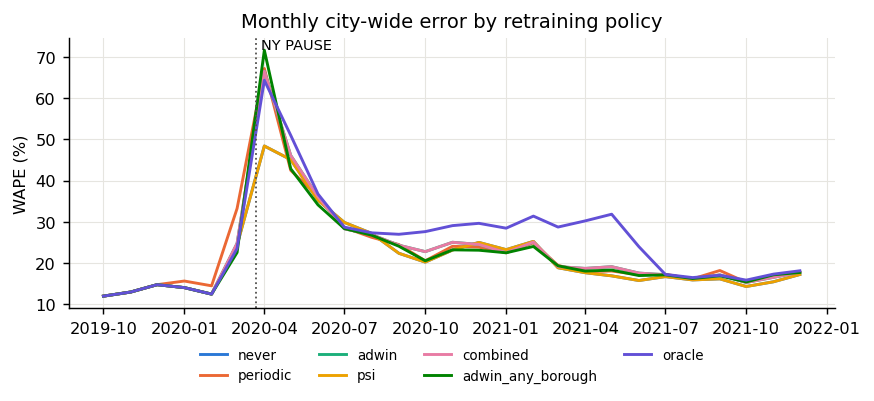

In [7]:
summ = pd.read_csv(R / "retraining" / "summary.csv")
cost = summ[summ.period == "cost"][["policy", "retrains", "promoted", "retrain_seconds"]]
err = summ[summ.period != "cost"]
piv = err[err.scope == "city"].pivot(index="policy", columns="period", values="wape").round(2)
display(piv.join(cost.set_index("policy")).round(1))
S["policies"] = json.loads(piv.join(cost.set_index("policy")).round(2).reset_index().to_json(orient="records"))

order = ["never", "periodic", "adwin", "psi", "combined", "adwin_any_borough", "oracle"]
fig, ax = plt.subplots(figsize=(6.8, 3.2))
for i, name in enumerate(order):
    f = R / "retraining" / f"{name}_daily.csv"
    if not f.exists():
        continue
    d = pd.read_csv(f, parse_dates=["day"])
    m = d[d.scope == "city"].set_index("day")[["abs_err", "demand"]].resample("MS").sum()
    ax.plot(m.index, 100 * m.abs_err / m.demand, color=COLORS[i], label=name)
ax.axvline(pd.Timestamp("2020-03-22"), color="#52514e", linestyle=":", linewidth=1)
ax.annotate("NY PAUSE", (pd.Timestamp("2020-03-22"), ax.get_ylim()[1]), fontsize=8, ha="left", va="top", xytext=(3, 0), textcoords="offset points")
ax.set(ylabel="WAPE (%)", title="Monthly city-wide error by retraining policy")
ax.legend(ncol=4, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
save(fig, "policy_error")

## 6. Fairness across boroughs

period,before (Oct 2019-Feb 2020),crash (Mar-Jun 2020),recovery (Jul 2020-Dec 2021),crash_over_before
scope,,,,
Bronx,114.30,131.48,114.47,1.15
Brooklyn,56.83,100.51,90.68,1.77
Manhattan,11.76,24.63,15.44,2.09
Queens,21.77,52.47,34.94,2.41
Staten Island,211.48,215.65,215.09,1.02


scope,Bronx,Brooklyn,Manhattan,Queens,Staten Island,worst_minus_best
policy,,,,,,
adwin,174.9,128.2,24.3,62.5,1255.9,1231.6
adwin_any_borough,169.4,124.0,22.6,59.9,1154.8,1132.2
combined,174.9,128.2,24.3,62.5,1255.9,1231.6
never,131.5,100.5,24.6,52.5,215.7,191.0
oracle,173.7,126.1,23.8,62.2,1288.3,1264.6
periodic,185.4,133.3,30.1,68.0,1582.3,1552.2
psi,131.5,100.5,24.6,52.5,215.7,191.0


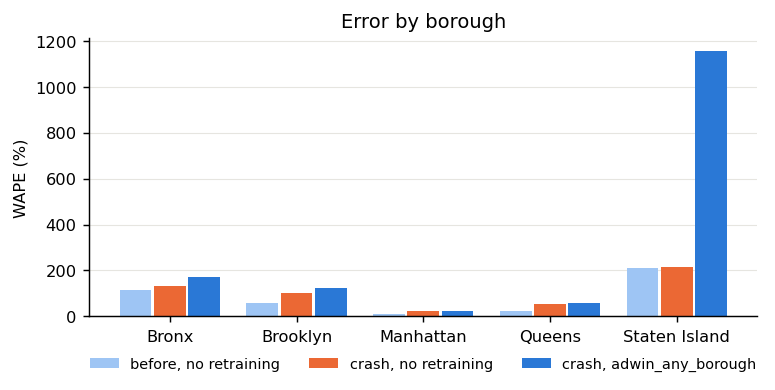

In [8]:
# Does drift hurt some boroughs more? Fixed model, error before against during the crash.
never = err[(err.policy == "never") & (err.scope != "city")]
w = never.pivot(index="scope", columns="period", values="wape")
w["crash_over_before"] = w["crash (Mar-Jun 2020)"] / w["before (Oct 2019-Feb 2020)"]
display(w.round(2))
S["borough_never"] = json.loads(w.round(2).reset_index().to_json(orient="records"))

best = cost.merge(piv.reset_index(), on="policy")
best = best[~best.policy.isin(["oracle", "never"])].sort_values("crash (Mar-Jun 2020)").policy.iloc[0]
S["best_policy"] = best
period = "crash (Mar-Jun 2020)"
gap = err[(err.period == period) & (err.scope != "city")].pivot(index="policy", columns="scope", values="wape")
gap["worst_minus_best"] = gap.max(axis=1) - gap.min(axis=1)
display(gap.round(1))
S["gap"] = json.loads(gap.round(2).reset_index().to_json(orient="records"))

boroughs = list(w.index)
fig, ax = plt.subplots(figsize=(6.2, 3.1))
x = range(len(boroughs))
vals = [("before, no retraining", w["before (Oct 2019-Feb 2020)"], "#9ec5f4"), ("crash, no retraining", w[period], COLORS[1]),
        (f"crash, {best}", gap.loc[best, boroughs], COLORS[0])]
for i, (lab, v, c) in enumerate(vals):
    ax.bar([k + (i - 1) * 0.27 for k in x], v, width=0.25, label=lab, color=c)
ax.set_xticks(list(x), boroughs)
ax.set(ylabel="WAPE (%)", title="Error by borough")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
save(fig, "borough_error")

detector_view,target,borough's own detector,city-wide detector,detector
0,Bronx,0.75,0.25,adwin_d0.002
1,Brooklyn,1.00,0.25,adwin_d0.002
2,Manhattan,1.00,1.00,adwin_d0.002
3,Queens,1.00,0.31,adwin_d0.002
4,Staten Island,0.38,0.34,adwin_d0.002
0,Bronx,0.62,0.00,psi_t0.25
1,Brooklyn,0.50,0.00,psi_t0.25
2,Manhattan,0.03,0.03,psi_t0.25
3,Queens,1.00,0.00,psi_t0.25
4,Staten Island,0.41,0.00,psi_t0.25


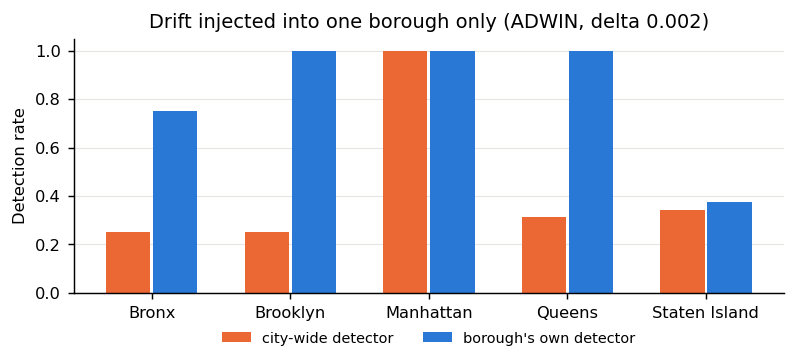

In [9]:
# Does a city-wide detector miss drift confined to one borough?
one = bench[(bench.target.isin(boroughs)) & (bench.target != "none")]
one = one.assign(detector_view=(one.stream_scope == "city").map({True: "city-wide detector", False: "borough's own detector"}))
adw = one[one.detector == "adwin_d0.002"]
psi_ = one[one.detector == "psi_t0.25"]
rows = []
for lab, part in [("adwin_d0.002", adw), ("psi_t0.25", psi_)]:
    t = part.groupby(["target", "detector_view"]).detected.mean().unstack()
    t["detector"] = lab
    rows.append(t.reset_index())
view = pd.concat(rows)
display(view.round(2))
S["city_vs_borough"] = json.loads(view.round(3).to_json(orient="records"))
pv = view[view.detector == "adwin_d0.002"].set_index("target").reindex(boroughs)
fig, ax = plt.subplots(figsize=(6.2, 2.9))
ax.bar([k - 0.17 for k in x], pv["city-wide detector"], width=0.32, label="city-wide detector", color=COLORS[1])
ax.bar([k + 0.17 for k in x], pv["borough's own detector"], width=0.32, label="borough's own detector", color=COLORS[0])
ax.set_xticks(list(x), boroughs)
ax.set(ylabel="Detection rate", ylim=(0, 1.05), title="Drift injected into one borough only (ADWIN, delta 0.002)")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
save(fig, "city_vs_borough")

## 7. Live pipeline run (Kafka and Spark, Feb-Apr 2020)

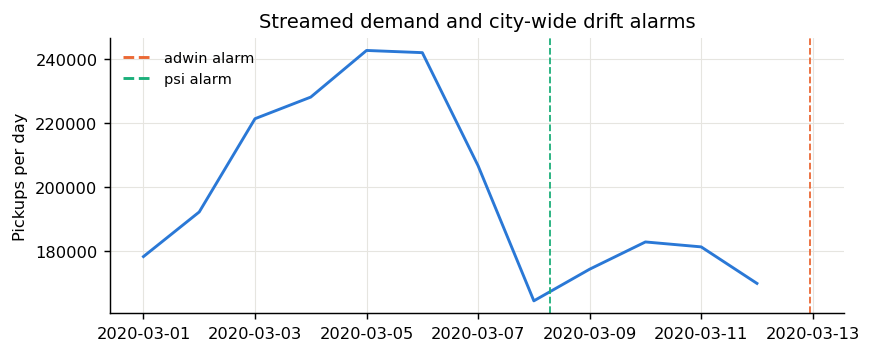

,timestamp,reason,promoted,challenger_wape,champion_wape,seconds
0,2020-03-12 23:00:00,adwin confirmed by psi warning,False,20.59,17.86,299.0


11005

In [10]:
p = R / "stream" / "monitor_hourly.csv"
if p.exists() and (R / "stream" / "monitor_alarms.csv").stat().st_size > 2:
    h = pd.read_csv(p, parse_dates=["hour"])
    al = pd.read_csv(R / "stream" / "monitor_alarms.csv", parse_dates=["timestamp"])
    fig, ax = plt.subplots(figsize=(6.8, 2.8))
    daily = h.set_index("hour").demand.resample("D").sum()
    ax.plot(daily.index, daily.values, color=COLORS[0])
    for det, c in [("adwin", COLORS[1]), ("psi", COLORS[2])]:
        for t in al[(al.detector == det) & (al.scope == "city")].timestamp:
            ax.axvline(t, color=c, linewidth=1, linestyle="--")
        ax.plot([], [], color=c, linestyle="--", label=f"{det} alarm")
    ax.set(ylabel="Pickups per day", title="Streamed demand and city-wide drift alarms")
    ax.legend(fontsize=8)
    save(fig, "live_run")
    S["live"] = {"hours": len(h), "alarms": len(al), "city_alarms": al[al.scope == "city"][["timestamp", "detector"]].astype(str).to_dict("records")}
    rp = R / "stream" / "monitor_retrains.csv"
    if rp.exists() and rp.stat().st_size > 2:
        r = pd.read_csv(rp)
        display(r.round(2))
        S["live"]["retrains"] = json.loads(r.round(2).to_json(orient="records"))
(R / "summary.json").write_text(json.dumps(S, indent=1, default=str))